## 1. Setup

In [1]:
from pathlib import Path
import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.transforms import functional as TF

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

SEED = 42
BATCH_SIZE = 32
EPOCHS = 15
LEARNING_RATE = 0.001

DATA_DIR = Path("road_dataset_224")   # Change this one line if the dataset is elsewhere.
CLASS_TO_IDX = {"Normal": 0, "Damaged": 1}
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

for split in ["train", "val", "test"]:
    if not (DATA_DIR / split).exists():
        raise FileNotFoundError(f"Missing folder: {DATA_DIR / split}")

RESULTS_DIR = Path("results/custom_cnn")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH = RESULTS_DIR / "best_custom_cnn.pth"

Device: cuda


## 2. Dataset and Class Weights

In [2]:
base_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

def remap_labels(dataset):
    dataset.samples = [
        (path, CLASS_TO_IDX[Path(path).parent.name])
        for path, _ in dataset.samples
    ]
    dataset.imgs = dataset.samples
    dataset.targets = [label for _, label in dataset.samples]
    dataset.class_to_idx = CLASS_TO_IDX.copy()
    dataset.classes = ["Normal", "Damaged"]
    return dataset

def load_split(split, transform):
    dataset = datasets.ImageFolder(DATA_DIR / split, transform=transform)
    return remap_labels(dataset)

train_dataset = load_split("train", base_transform)
val_dataset = load_split("val", base_transform)
test_dataset = load_split("test", base_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

for name, dataset in [("Train", train_dataset), ("Validation", val_dataset), ("Test", test_dataset)]:
    counts = np.bincount(dataset.targets, minlength=2)
    print(f"{name}: Normal={counts[0]}, Damaged={counts[1]}, Total={len(dataset)}")

train_counts = np.bincount(train_dataset.targets, minlength=2)
class_weights = torch.tensor(
    len(train_dataset) / (2.0 * train_counts),
    dtype=torch.float32,
    device=device
)
print(f"Class weights -> Normal: {class_weights[0]:.4f}, Damaged: {class_weights[1]:.4f}")

Train: Normal=928, Damaged=2470, Total=3398
Validation: Normal=198, Damaged=529, Total=727
Test: Normal=200, Damaged=531, Total=731
Class weights -> Normal: 1.8308, Damaged: 0.6879


## 3. Model

In [3]:
class CustomCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.pool = nn.MaxPool2d(2, 2)
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.conv4 = nn.Conv2d(128, 256, 3, padding=1)
        self.fc1 = nn.Linear(256 * 14 * 14, 128)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, 2)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = self.pool(torch.relu(self.conv3(x)))
        x = self.pool(torch.relu(self.conv4(x)))
        x = torch.flatten(x, 1)
        x = torch.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)

model = CustomCNN().to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

print(model)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

CustomCNN(
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=50176, out_features=128, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=128, out_features=2, bias=True)
)
Trainable parameters: 6,811,330


## 4. Training and Validation

Epoch 01/15 | Train Loss: 0.5247 | Val Loss: 0.4113
Epoch 02/15 | Train Loss: 0.4083 | Val Loss: 0.4240
Epoch 03/15 | Train Loss: 0.3649 | Val Loss: 0.4792
Epoch 04/15 | Train Loss: 0.3407 | Val Loss: 0.2839
Epoch 05/15 | Train Loss: 0.3057 | Val Loss: 0.3268
Epoch 06/15 | Train Loss: 0.2895 | Val Loss: 0.2744
Epoch 07/15 | Train Loss: 0.2487 | Val Loss: 0.2531
Epoch 08/15 | Train Loss: 0.2423 | Val Loss: 0.3308
Epoch 09/15 | Train Loss: 0.2086 | Val Loss: 0.2923
Epoch 10/15 | Train Loss: 0.1813 | Val Loss: 0.2490
Epoch 11/15 | Train Loss: 0.1682 | Val Loss: 0.2620
Epoch 12/15 | Train Loss: 0.1529 | Val Loss: 0.2900
Epoch 13/15 | Train Loss: 0.1306 | Val Loss: 0.3321
Epoch 14/15 | Train Loss: 0.0933 | Val Loss: 0.2971
Epoch 15/15 | Train Loss: 0.0828 | Val Loss: 0.3235

Best epoch: 10 | Best validation loss: 0.2490


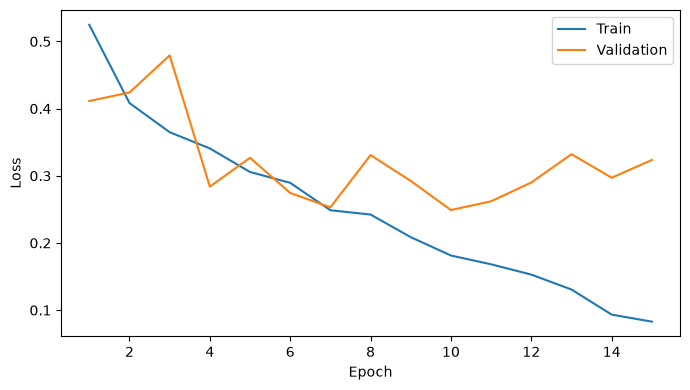

In [4]:
history = []
best_val_loss = float("inf")
best_epoch = 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss = 0.0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = criterion(model(images), labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            val_loss += criterion(model(images), labels).item()

    train_loss /= len(train_loader)
    val_loss /= len(val_loader)
    history.append({"Epoch": epoch, "Train Loss": train_loss, "Validation Loss": val_loss})

    if val_loss < best_val_loss:
        best_val_loss, best_epoch = val_loss, epoch
        torch.save(model.state_dict(), BEST_MODEL_PATH)

    print(f"Epoch {epoch:02d}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

print(f"\nBest epoch: {best_epoch} | Best validation loss: {best_val_loss:.4f}")

history_df = pd.DataFrame(history)
history_df.to_csv(RESULTS_DIR / "training_history.csv", index=False)

plt.figure(figsize=(7, 4))
plt.plot(history_df["Epoch"], history_df["Train Loss"], label="Train")
plt.plot(history_df["Epoch"], history_df["Validation Loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "loss_curve.png", dpi=200)
plt.show()

## 5. Final Test Evaluation


Final Test Results
Accuracy: 0.9083
Precision: 0.9585
Recall: 0.9134
F1: 0.9354

Classification Report:
              precision    recall  f1-score   support

      Normal       0.80      0.90      0.84       200
     Damaged       0.96      0.91      0.94       531

    accuracy                           0.91       731
   macro avg       0.88      0.90      0.89       731
weighted avg       0.91      0.91      0.91       731



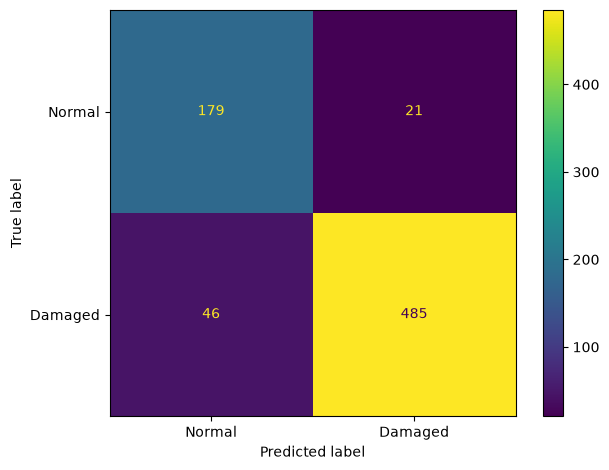

In [5]:
def evaluate(model, loader):
    y_true, y_pred = [], []

    model.eval()
    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images.to(device))
            predictions = outputs.argmax(dim=1).cpu().numpy()
            y_pred.extend(predictions)
            y_true.extend(labels.numpy())

    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "F1": f1_score(y_true, y_pred, pos_label=1, zero_division=0)
    }
    return metrics, np.array(y_true), np.array(y_pred)

def robustness_transform(brightness=1.0, blur=None):
    steps = [transforms.Resize((224, 224))]

    if brightness != 1.0:
        steps.append(transforms.Lambda(lambda img, f=brightness: TF.adjust_brightness(img, f)))

    if blur is not None:
        kernel_size, sigma = blur
        steps.append(transforms.GaussianBlur(kernel_size=kernel_size, sigma=sigma))

    steps += [transforms.ToTensor(), transforms.Normalize(MEAN, STD)]
    return transforms.Compose(steps)

ROBUSTNESS_CONDITIONS = {
    "Clean": {"brightness": 1.0, "blur": None},
    "Low Brightness (0.7)": {"brightness": 0.7, "blur": None},
    "High Brightness (1.3)": {"brightness": 1.3, "blur": None},
    "Mild Blur (k=5, sigma=1.0)": {"brightness": 1.0, "blur": (5, 1.0)},
    "Strong Blur (k=9, sigma=2.0)": {"brightness": 1.0, "blur": (9, 2.0)}
}

def run_robustness(model):
    rows = []
    for condition, settings in ROBUSTNESS_CONDITIONS.items():
        dataset = load_split("test", robustness_transform(**settings))
        loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
        metrics, _, _ = evaluate(model, loader)
        rows.append({"Condition": condition, **metrics})
    return pd.DataFrame(rows)

model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
test_metrics, y_true, y_pred = evaluate(model, test_loader)

print("\nFinal Test Results")
for name, value in test_metrics.items():
    print(f"{name}: {value:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    labels=[0, 1],
    target_names=["Normal", "Damaged"],
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["Normal", "Damaged"]).plot(values_format="d")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=200)
plt.show()

pd.DataFrame([test_metrics]).to_csv(RESULTS_DIR / "clean_test_metrics.csv", index=False)

## 6. Robustness Evaluation

In [6]:
robustness_results = run_robustness(model)
robustness_results.to_csv(RESULTS_DIR / "robustness_results.csv", index=False)

print(robustness_results.to_string(
    index=False,
    formatters={c: "{:.4f}".format for c in ["Accuracy", "Precision", "Recall", "F1"]}
))

                   Condition Accuracy Precision Recall     F1
                       Clean   0.9083    0.9585 0.9134 0.9354
        Low Brightness (0.7)   0.8167    0.9501 0.7891 0.8621
       High Brightness (1.3)   0.9083    0.9312 0.9435 0.9373
  Mild Blur (k=5, sigma=1.0)   0.7168    0.9821 0.6215 0.7612
Strong Blur (k=9, sigma=2.0)   0.5718    0.9781 0.4200 0.5876
